In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [41]:
df = pd.read_csv('./grocerydb.csv')
df.head()

,name,store,category,brand,FPro,FPro_class,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.8930,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.8930,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583219,3.0,2.79,0.055973,90.7184,1.098901,0.549451,13.186813,7.692308,2.197802,0.010989,0.000000
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451056,0.0,2.49,0.019213,90.7184,5.494505,7.692308,15.384615,8.791209,3.296703,0.000000,0.000000
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.773519,3.0,4.99,0.017781,396.8930,3.030303,1.010101,14.141414,6.060606,2.020202,0.050505,0.005051


In [42]:
df.shape

(26250, 16)

In [45]:
clean_mask = (
    df["store"].isin(["Walmart", "Target", "WholeFoods"])
    & df["FPro_class"].isin([0, 1, 2, 3])
    & (df["price percal"] > 0)
)
df_clean = df[clean_mask].copy()
df_clean.head()

,name,store,category,brand,FPro,FPro_class,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.8930,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.8930,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583219,3.0,2.79,0.055973,90.7184,1.098901,0.549451,13.186813,7.692308,2.197802,0.010989,0.000000
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451056,0.0,2.49,0.019213,90.7184,5.494505,7.692308,15.384615,8.791209,3.296703,0.000000,0.000000
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.773519,3.0,4.99,0.017781,396.8930,3.030303,1.010101,14.141414,6.060606,2.020202,0.050505,0.005051


In [47]:
df_clean.shape

(20780, 16)

In [49]:
# Convert to consumer-friendly metric: $ per 1,000 kcal
df_clean["price_per_1000kcal"] = df_clean["price percal"] * 1000
df_clean.head()

,name,store,category,brand,FPro,FPro_class,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol,price_per_1000kcal
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.8930,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101,43.984147
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.8930,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101,43.984147
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583219,3.0,2.79,0.055973,90.7184,1.098901,0.549451,13.186813,7.692308,2.197802,0.010989,0.000000,55.973209
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451056,0.0,2.49,0.019213,90.7184,5.494505,7.692308,15.384615,8.791209,3.296703,0.000000,0.000000,19.213302
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.773519,3.0,4.99,0.017781,396.8930,3.030303,1.010101,14.141414,6.060606,2.020202,0.050505,0.005051,17.781331


In [51]:
catalog_composition = (
    pd.crosstab(
        df_clean["store"],
        df_clean["FPro_class"],
        normalize="index",
    )
    * 100
).round(1)

# Ensure readable column headers
catalog_composition.columns = [
    "NOVA_0_MinimallyProcessed",
    "NOVA_1_CulinaryIngredients",
    "NOVA_2_Processed",
    "NOVA_3_UltraProcessed",
]

nova3_df = df_clean[df_clean["FPro_class"] == 3]

price_summary = (
    nova3_df.groupby("store")["price_per_1000kcal"]
    .agg(
        count="count",
        q25=lambda x: x.quantile(0.25),
        median="median",
        q75=lambda x: x.quantile(0.75),
    )
    .round(2)
)

print("--- Catalog Composition (%) ---")
print(catalog_composition)
print("\n--- NOVA 3 Price per 1,000 Calories ($) ---")
print(price_summary)

--- Catalog Composition (%) ---
            NOVA_0_MinimallyProcessed  NOVA_1_CulinaryIngredients  \
store                                                               
Target                            5.5                         0.9   
Walmart                           8.6                         1.6   
WholeFoods                       19.7                         3.4   

            NOVA_2_Processed  NOVA_3_UltraProcessed  
store                                                
Target                   9.0                   84.6  
Walmart                  8.7                   81.2  
WholeFoods               9.9                   67.0  

--- NOVA 3 Price per 1,000 Calories ($) ---
            count   q25  median    q75
store                                 
Target       5370  2.89    5.30  10.86
Walmart      5993  1.97    3.21   6.27
WholeFoods   4724  5.21    8.56  14.90


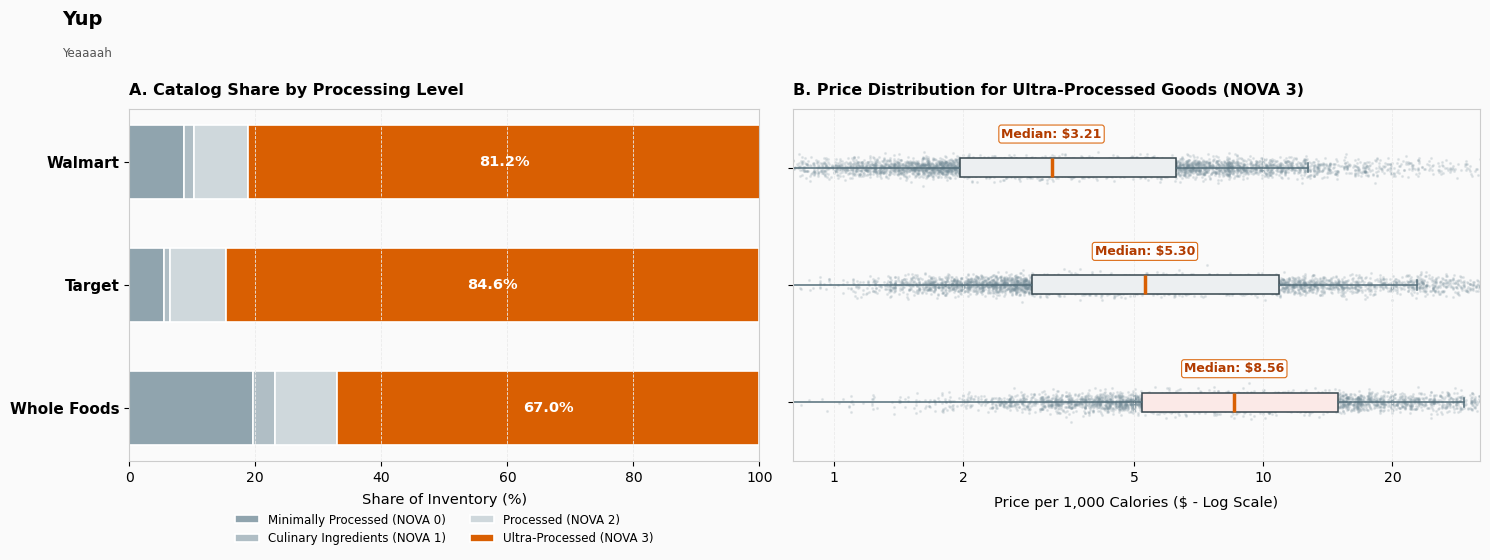

In [69]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


# ===================================================
# ==================== STYLING ======================
# ===================================================

plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
        "axes.edgecolor": "#CCCCCC",
        "axes.linewidth": 0.8,
        "grid.color": "#EBEBEB",
        "grid.linestyle": "--",
        "grid.linewidth": 0.6,
    }
)

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1.2]}
)
fig.patch.set_facecolor("#FAFAFA")
ax1.set_facecolor("#FAFAFA")
ax2.set_facecolor("#FAFAFA")

store_order = ["Walmart", "Target", "WholeFoods"]
store_labels = ["Walmart", "Target", "Whole Foods"]
colors_nova = {
    0: "#90A4AE",
    1: "#B0BEC5",
    2: "#CFD8DC",
    3: "#D95F02",
}

# ===================================================
# ============== PANEL A: COMPOSITION ===============
# ===================================================

# Data pulled from the information before 
comp_data = {
    "Walmart": [8.6, 1.6, 8.7, 81.2],
    "Target": [5.5, 0.9, 9.0, 84.6],
    "WholeFoods": [19.7, 3.4, 9.9, 67.0],
}
y_pos = np.arange(len(store_order))
bar_height = .6
lefts = np.zeros(len(store_order))

legend_labels = [
    "Minimally Processed (NOVA 0)",
    "Culinary Ingredients (NOVA 1)",
    "Processed (NOVA 2)",
    "Ultra-Processed (NOVA 3)",
]

for i in range(4):
    vals = [comp_data[s][i] for s in store_order]
    bars = ax1.barh(
        y_pos,
        vals,
        left=lefts,
        height=bar_height,
        color=colors_nova[i],
        edgecolor="white",
        linewidth=1.2,
        label=legend_labels[i],
    )
    if i == 3:
        for idx, rect in enumerate(bars):
            ax1.text(
                rect.get_x() + rect.get_width() / 2,
                rect.get_y() + bar_height / 2,
                f"{vals[idx]:.1f}%",
                va="center",
                ha="center",
                color="white",
                fontweight="bold",
                fontsize=10.5,
            )
    lefts += np.array(vals)

ax1.set_yticks(y_pos)
ax1.set_yticklabels(store_labels, fontsize=11, fontweight="bold")
ax1.invert_yaxis()
ax1.set_xlabel("Share of Inventory (%)", fontsize=10.5, labelpad=6)
ax1.set_xlim(0, 100)
ax1.xaxis.grid(True)
ax1.yaxis.grid(False)
ax1.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, -0.27),
    ncol=2,
    frameon=False,
    fontsize=8.5,
)
ax1.set_title(
    "A. Catalog Share by Processing Level",
    fontsize=11.5,
    fontweight="bold",
    pad=10,
    loc="left",
)

# ===================================================
# =================== PANEL B =======================
# ===================================================

nova3_df = df_clean[df_clean["FPro_class"] == 3].copy()
medians = {"Walmart": 3.21, "Target": 5.30, "WholeFoods": 8.56}

# Soft colors mapping back to the store groups
box_colors = ["#ECEFF1", "#ECEFF1", "#FBE9E7"]

for idx, store in enumerate(store_order):
    store_data = nova3_df[nova3_df["store"] == store]["price_per_1000kcal"]

    # Jittered strip plot background
    jitter = np.random.normal(0, 0.04, size=len(store_data))
    ax2.scatter(
        store_data,
        idx + jitter,
        color="#78909C",
        alpha=0.15,
        s=1.5,
        zorder=1,
    )

    # Boxplot overlay
    bp = ax2.boxplot(
        store_data,
        positions=[idx],
        vert=False,
        widths=0.16,
        patch_artist=True,
        showfliers=False,
        zorder=2,
        medianprops=dict(color="#D95F02", linewidth=2.5),
        whiskerprops=dict(color="#546E7A", linewidth=1.1),
        capprops=dict(color="#546E7A", linewidth=1.1),
    )
    bp["boxes"][0].set_facecolor(box_colors[idx])
    bp["boxes"][0].set_edgecolor("#37474F")
    bp["boxes"][0].set_linewidth(1.1)

    # Place high-contrast median badges
    med_val = medians[store]
    ax2.text(
        med_val,
        idx - 0.23,
        f"Median: ${med_val:.2f}",
        ha="center",
        va="bottom",
        fontweight="bold",
        color="#B23C00",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="#D95F02",
            lw=0.8,
            alpha=0.92,
        ),
    )

ax2.set_xscale("log")
ax2.set_yticks(y_pos)
ax2.set_yticklabels([])  # Row-aligned directly with Panel A
ax2.invert_yaxis()
ax2.set_xlabel("Price per 1,000 Calories ($ - Log Scale)", fontsize=10.5, labelpad=8)
ax2.xaxis.grid(True)
ax2.yaxis.grid(False)

# Use strict custom label ticks instead of confusing exponent defaults
ax2.set_xlim(0.8, 32.0)
ax2.set_xticks([1.0, 2.0, 5.0, 10.0, 20.0])
ax2.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax2.get_xaxis().set_tick_params(which="minor", size=0)  # Suppress minor noise

ax2.set_title(
    "B. Price Distribution for Ultra-Processed Goods (NOVA 3)",
    fontsize=11.5,
    fontweight="bold",
    pad=10,
    loc="left",
)

# =========================================================
# ============= GLOBAL HEADER / TYPOGRAPHY LAYER ==========
# =========================================================

fig.suptitle(
    "Yup",
    fontsize=14.0,
    fontweight="bold",
    x=0.045,
    y=1.04,
    ha="left",
)

plt.figtext(
    0.045,
    0.955,
    "Yeaaaah",
    fontsize=8.5,
    color="#555555",
    ha="left",
)

plt.tight_layout()
plt.subplots_adjust(top=0.86, bottom=0.22)
plt.savefig("healthy_halo_tax_final.png", dpi=300, bbox_inches="tight")
plt.show()

